<a href="https://colab.research.google.com/github/glopro122/Airport/blob/main/planeta2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt
import math

In [11]:
# Constantes
G = 6.67428e-11
M_sol = 1.9890e30
UA = 1.496e11  # Unidad Astronómica en metros

# Condiciones iniciales
x0 = UA
y0 = 0.0

vx0 = 0.0
vy0 = 29.783e3

# Tiempo
dt = 3600 * 24      # 1 día en segundos
T_total = 3.154e7   # 1 año aprox.
N_pasos = int(T_total / dt)

print("Variables iniciales listas")


Variables iniciales listas


In [12]:
def calcular_aceleracion(x, y):
    r = math.sqrt(x**2 + y**2)
    a_mag = -G * M_sol / (r**2)

    ax = a_mag * (x / r)
    ay = a_mag * (y / r)

    return ax, ay

In [13]:
def metodo_verlet(x, y, vx, vy, n_pasos, dt):
    trayectoria = []

    for _ in range(n_pasos):
        ax, ay = calcular_aceleracion(x, y)

        x_nuevo = x + vx * dt + 0.5 * ax * dt**2
        y_nuevo = y + vy * dt + 0.5 * ay * dt**2

        ax_nuevo, ay_nuevo = calcular_aceleracion(x_nuevo, y_nuevo)

        vx = vx + 0.5 * (ax + ax_nuevo) * dt
        vy = vy + 0.5 * (ay + ay_nuevo) * dt

        x, y = x_nuevo, y_nuevo

        trayectoria.append((x, y))

    return trayectoria

In [14]:
def metodo_euler(x, y, vx, vy, n_pasos, dt):
    trayectoria = []

    for _ in range(n_pasos):
        ax, ay = calcular_aceleracion(x, y)

        vx = vx + ax * dt
        vy = vy + ay * dt

        x = x + vx * dt
        y = y + vy * dt

        trayectoria.append((x, y))

    return trayectoria

In [15]:
trayectoria_euler = metodo_euler(x0, y0, vx0, vy0, N_pasos, dt)
trayectoria_verlet = metodo_verlet(x0, y0, vx0, vy0, N_pasos, dt)

print("Euler y Verlet ejecutados correctamente")
print("Puntos Euler:", len(trayectoria_euler))
print("Puntos Verlet:", len(trayectoria_verlet))

Euler y Verlet ejecutados correctamente
Puntos Euler: 365
Puntos Verlet: 365


In [16]:
x_euler = [p[0] for p in trayectoria_euler]
y_euler = [p[1] for p in trayectoria_euler]

x_verlet = [p[0] for p in trayectoria_verlet]
y_verlet = [p[1] for p in trayectoria_verlet]

print("Coordenadas separadas correctamente")

Coordenadas separadas correctamente


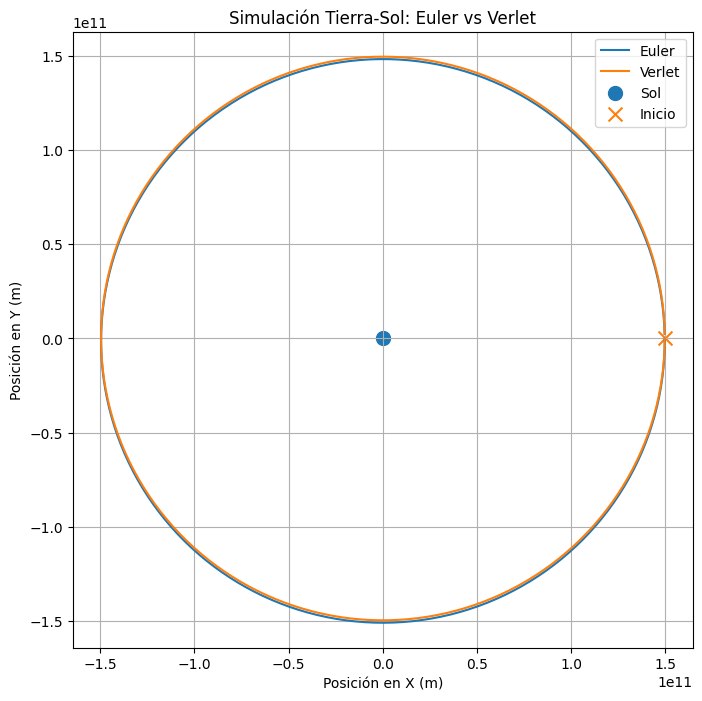

In [17]:
plt.figure(figsize=(8, 8))

plt.plot(x_euler, y_euler, label="Euler")
plt.plot(x_verlet, y_verlet, label="Verlet")

plt.scatter(0, 0, marker='o', s=100, label="Sol")
plt.scatter(x0, y0, marker='x', s=100, label="Inicio")

plt.xlabel("Posición en X (m)")
plt.ylabel("Posición en Y (m)")
plt.title("Simulación Tierra-Sol: Euler vs Verlet")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

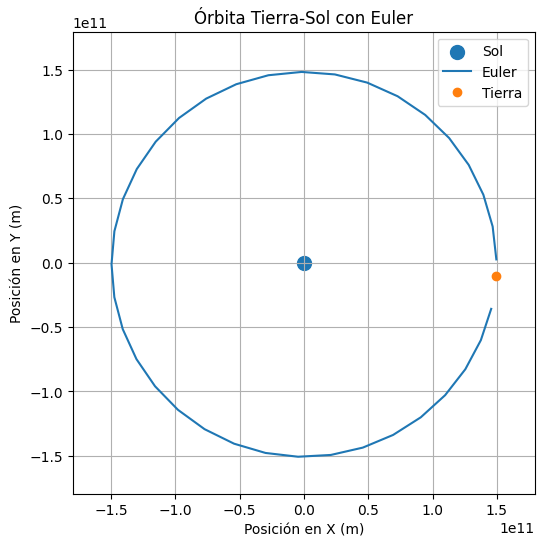

In [18]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

salto = 10  # entre más grande, más liviana la animación

x_e = x_euler[::salto]
y_e = y_euler[::salto]

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-UA * 1.2, UA * 1.2)
ax.set_ylim(-UA * 1.2, UA * 1.2)
ax.set_aspect("equal")
ax.grid(True)

ax.set_title("Órbita Tierra-Sol con Euler")
ax.set_xlabel("Posición en X (m)")
ax.set_ylabel("Posición en Y (m)")

ax.scatter(0, 0, s=100, label="Sol")
linea, = ax.plot([], [], label="Euler")
punto, = ax.plot([], [], 'o', markersize=6, label="Tierra")

ax.legend()

def init():
    linea.set_data([], [])
    punto.set_data([], [])
    return linea, punto

def update(frame):
    linea.set_data(x_e[:frame], y_e[:frame])
    punto.set_data([x_e[frame]], [y_e[frame]])
    return linea, punto

ani = FuncAnimation(
    fig,
    update,
    frames=len(x_e),
    init_func=init,
    interval=60,
    blit=True
)

HTML(ani.to_jshtml())

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.set_xlim(-UA * 1.2, UA * 1.2)
ax.set_ylim(-UA * 1.2, UA * 1.2)
ax.set_aspect('equal')
ax.grid(True)
ax.set_title("Órbita Tierra-Sol con Verlet")
ax.set_xlabel("Posición en X (m)")
ax.set_ylabel("Posición en Y (m)")

# Sol
ax.scatter(0, 0, s=150, label="Sol")

# Línea de trayectoria y punto móvil
linea_verlet, = ax.plot([], [], label="Trayectoria Verlet")
punto_verlet, = ax.plot([], [], 'o', markersize=8, label="Tierra")

ax.legend()

def init_verlet():
    linea_verlet.set_data([], [])
    punto_verlet.set_data([], [])
    return linea_verlet, punto_verlet

def update_verlet(frame):
    linea_verlet.set_data(x_verlet[:frame], y_verlet[:frame])
    punto_verlet.set_data([x_verlet[frame]], [y_verlet[frame]])
    return linea_verlet, punto_verlet

ani_verlet = FuncAnimation(
    fig,
    update_verlet,
    frames=len(x_verlet),
    init_func=init_verlet,
    interval=30,
    blit=True
)

HTML(ani_verlet.to_jshtml())